**About:** Cell Tracking — TemporalUNet3D + SimpleNodeTransformer Inference

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd ../src

/data/kaggle-cell-tracking/src


In [3]:
import os
import glob
import json
import torch
import zarr
import polars as pl
import numpy as np
import pandas as pd
import tracksdata as td
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from pathlib import Path
from collections import Counter

In [4]:
from tracking.post_process import detect_peaks
from tracking.plot import plot_detection, plot_edges, plot_sample

from model_zoo.models_track import define_track_model, UNetNodeTransformer
from tracking_cellmot.io import open_dataset, list_datasets


In [5]:
from utils.metrics import match_frame_nodes
from tracking.post_process import build_graph
from tracking_cellmot.metrics import evaluate, node_recall, per_sample_metrics, summarise

from utils.plot import plot_contours, scatter_plot_center_preds
from tracking.predict import load_track_model, predict_video, PredictConfig

In [6]:
import contextlib
import os

@contextlib.contextmanager
def suppress_output():
    """Context manager to suppress stdout and stderr."""
    with open(os.devnull, "w") as devnull:
        with contextlib.redirect_stdout(devnull), contextlib.redirect_stderr(devnull):
            yield


In [7]:
from params import TRAIN_DIR, LOG_FOLDER, SCALE

TRAIN_DIR = Path(TRAIN_DIR)
LOG_FOLDER = Path(LOG_FOLDER)

WINDOW_SIZE = 2

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


In [77]:
LOG_FOLDER = "../logs/2026-08-13/27/"
FOLD = 0

### Model

In [78]:
from utils.logger import Config
from tracking.main import build_model

In [79]:
cfg = Config(json.load(open(LOG_FOLDER + "args.json", "r")))

In [80]:
checkpoints = sorted(glob.glob(LOG_FOLDER + f"fold_{FOLD}/ckpt_*.pt", recursive=True))
if checkpoints:
    ckpt_path = checkpoints[-1]
    print(f"Loading: {ckpt_path}")
else:
    ckpt_path = None
    print("No checkpoint found — run train_track.sh first.")

Loading: ../logs/2026-08-13/27/fold_0/ckpt_best.pt


In [81]:
model = build_model(cfg, None)
model.eval().to(device)

ckpt = torch.load(ckpt_path)
state = ckpt.get("model_state_dict", ckpt)
model.load_state_dict(state, strict=True)

<All keys matched successfully>

### Data

In [149]:
from tracking.main import _paths_for_embryos

paths = _paths_for_embryos(TRAIN_DIR, "6bba")
paths[0]

PosixPath('../input/train/6bba_05b6850b')

In [150]:
# sample_name = "6bba_09961292"
sample_name = "44b6_0113de3b"
sample_name = "6bba_05b6850b"

In [151]:
df = pd.read_csv(f"../input/metadata.csv")

In [152]:
tracks_path = TRAIN_DIR / f"{sample_name}.geff"
result = td.graph.IndexedRXGraph.from_geff(tracks_path)
gt_graph = result[0] if isinstance(result, tuple) else result

node_attrs = gt_graph.node_attrs()

In [153]:
vol = zarr.open_group(str(TRAIN_DIR / f'{sample_name}.zarr'), mode="r")["0"]

In [154]:
# sample_name = "44b6_0113de3b"

# ref_preds = td.graph.IndexedRXGraph.from_geff(f"../output/{sample_name}.geff")[0]
# ref_nodes = ref_preds.node_attrs()
# ref_edges = ref_preds.edge_attrs()

# res = evaluate(ref_preds, gt_graph, scale=SCALE)

# node_recall_ = node_recall(ref_preds, gt_graph)
# print(f"- Node recall: {node_recall_:.3f}")

# n_total = df[df['sample_name'] == tracks_path.stem]["estimated_number_of_nodes"].values[0]
# print(f"- Estimated number of nodes: {n_total}")

# metrics = per_sample_metrics(res, n_total, node_recall_)
# metrics = summarise([metrics])

# for k in ["edge_tp", "edge_fp", "edge_fn"]:
#     print(f"- {k}: {metrics[k]:.0f}")
# for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
#     print(f"- {k}: {metrics[k]:.3f}")

### Predict

In [155]:
from tracking.predict import predict_video, PredictConfig

In [156]:
from dataclasses import dataclass

@dataclass
class PredictConfig:
    """Hyperparameters that affect prediction quality.

    Detection
    ---------
    det_threshold : float
        Minimum sigmoid probability for a local-max peak to be kept.
    det_tta : bool
        Average detection logits over Y/X flips. Z is excluded because the
        data is anisotropic (Z is ~4x coarser), so Z-flips are out of
        distribution.
    pool_kernel_um : float
        Max-pool NMS kernel size in microns.

    Edge filtering
    --------------
    edge_activation : str
        ``"softmax"`` (normalised over parents) or ``"sigmoid"``.
    edge_threshold : float
        Minimum edge probability to consider a link.
    max_parents_per_node : int or None
        Maximum incoming edges per node (1 = no merges).
    max_children_per_node : int or None
        Maximum outgoing edges per node (2 = divisions allowed).
    """

    det_threshold: float = 0.5
    det_tta: bool = True
    pool_kernel_um: float = 3.0

    edge_activation: str = "softmax"
    edge_threshold: float = 0.5
    max_parents_per_node: int | None = 1
    max_children_per_node: int | None = 2

In [157]:
cfg = PredictConfig(
    det_threshold=0.5,
    det_tta=False,
    pool_kernel_um=5.0,
    edge_activation="softmax",
    edge_threshold=0.1,
    max_parents_per_node=1,
    max_children_per_node=2,
)

In [158]:
coords, edges = predict_video(
    model,
    TRAIN_DIR / sample_name,
    device=device,
    cfg=cfg,
    window_size=WINDOW_SIZE,
)

# coords: (N, 4) [t, z, y, x] in ORIGINAL resolution
# edges:  list of (src_idx, tgt_idx, prob, distance) indexing rows of coords
print(f"coords {coords.shape}  |  {len(edges)} edges")

coords (1066, 4)  |  1025 edges


In [159]:
matched = 0
total = 0

for frame in np.arange(0, 100)[::-1]:
    preds = coords[coords[:, 0] == frame][:, 1:]

    # preds = ref_nodes.to_pandas()
    # preds = preds[preds["t"] == frame][["z", "y", "x"]].values

    gt = node_attrs.to_pandas()
    gt = gt[gt["t"] == frame][["z", "y", "x"]].values

    if len(gt):
        pairs, matched_gt, unmatched_gt = match_frame_nodes(
            preds,
            gt,
            t=frame,
            scale=SCALE,
            max_distance=7,
        )
        matched += len(matched_gt)
        total += len(gt)

        # print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

recall = matched / total
print(f"Node Recall: {recall:.3f}")

Node Recall: 0.049


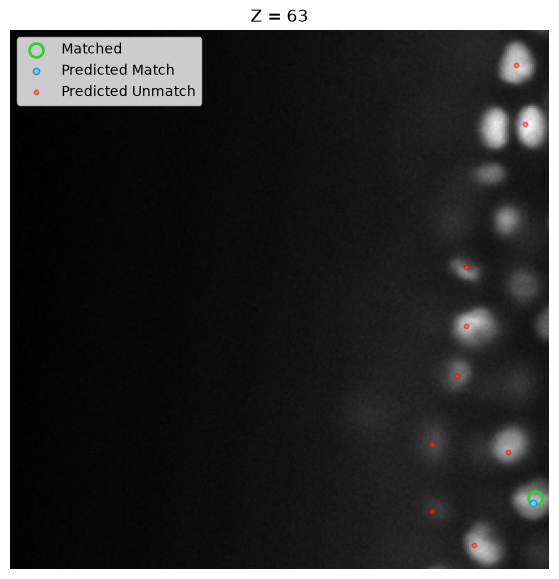

In [145]:
img = vol[frame]

ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else np.unique(gt[:, 0])
# ids = np.unique(gt[:, 0])

tol = 3

for i in ids:    
    plt.figure(figsize=(7, 7))
    plt.title(f"Z = {i}")
    plt.imshow(img[i], cmap="gray")
    plt.axis("off")
    # break
    scatter_plot_center_preds(preds, matched_gt, unmatched_gt, frame=i, tol=tol)
    plt.show()

    break

In [146]:
graph = build_graph(coords, edges)


8329


In [147]:
res = evaluate(graph, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

n_total = df[df['sample_name'] == tracks_path.stem]["estimated_number_of_nodes"].values[0]
print(f"- Estimated number of nodes: {n_total}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

- Node recall: 0.577
- Estimated number of nodes: 25755
- edge_tp: 1
- edge_fp: 4
- edge_fn: 49
- edge_jaccard: 0.019
- adj_edge_jaccard: 0.020
- division_jaccard: 0.000
- score: 0.020


### ILP

In [45]:
# ILD_EDGE_W = -1.0 
# ILP_APPEARANCE_W = 0.1 
# ILP_DISAPPEARANCE_W = 0.1 
# ILP_DIVISION_W = 1.0

# solver = td.solvers.ILPSolver(
#     edge_weight=ILD_EDGE_W * td.EdgeAttr("edge_prob"),
#     appearance_weight=ILP_APPEARANCE_W,
#     disappearance_weight=ILP_DISAPPEARANCE_W,
#     division_weight=ILP_DIVISION_W,
    
# )
# with suppress_output():
#     graph_ilp = solver.solve(graph)

In [46]:
# with suppress_output():
#     res = evaluate(graph_ilp.detach(), gt_graph, scale=SCALE)

# node_recall_ = node_recall(graph_ilp, gt_graph)
# print(f"- Node recall: {node_recall_:.3f}")

# n_total = df[df['sample_name'] == tracks_path.stem]["estimated_number_of_nodes"].values[0]
# print(f"- Estimated number of nodes: {n_total}")

# metrics = per_sample_metrics(res, n_total, node_recall_)
# metrics = summarise([metrics])

# for k in ["edge_tp", "edge_fp", "edge_fn"]:
#     print(f"- {k}: {metrics[k]:.0f}")
# for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
#     print(f"- {k}: {metrics[k]:.3f}")

In [ ]:
import os
import tracksdata as td
import numpy as np
import blosc2
import math
from scipy.optimize import linear_sum_assignment
import json
from pathlib import Path
import csv
import pandas as pd
from IPython.display import display


SUBMISSION_COLUMNS = ["dataset", "row_type", "node_id", "t", "z", "y", "x", "source_id", "target_id"]
CSV_COLUMNS = ["id", *SUBMISSION_COLUMNS]
VOXEL_SCALE_UM = (1.625, 0.40625, 0.40625)

# Output-level graph post-processing.
OUTPUT_EDGE_MAX_UM = float(os.environ.get("BIOHUB_OUTPUT_EDGE_MAX_UM", "14.2"))
OUTPUT_ENFORCE_NEXT_FRAME = os.environ.get("BIOHUB_OUTPUT_ENFORCE_NEXT_FRAME", "1") != "0"
OUTPUT_SINGLE_PARENT_REPAIR = os.environ.get("BIOHUB_OUTPUT_SINGLE_PARENT_REPAIR", "1") != "0"
OUTPUT_SINGLE_CHILD_REPAIR = os.environ.get("BIOHUB_OUTPUT_SINGLE_CHILD_REPAIR", "0") != "0"
OUTPUT_PRUNE_ISOLATED = os.environ.get("BIOHUB_OUTPUT_PRUNE_ISOLATED", "1") != "0"
OUTPUT_MOTION_RELINK = os.environ.get("BIOHUB_OUTPUT_MOTION_RELINK", "1") != "0"
MOTION_RELINK_TIGHT_UM = float(os.environ.get("BIOHUB_MOTION_RELINK_TIGHT_UM", "5.95"))
MOTION_RELINK_RELAXED_UM = float(os.environ.get("BIOHUB_MOTION_RELINK_RELAXED_UM", "10.0"))
MOTION_RELINK_VELOCITY_WEIGHT = float(os.environ.get("BIOHUB_MOTION_RELINK_VELOCITY_WEIGHT", "0.50"))
MOTION_RELINK_LEARNED_BONUS = float(os.environ.get("BIOHUB_MOTION_RELINK_LEARNED_BONUS", "0.76"))
MOTION_RELINK_MAX_FRAME_NODES = int(os.environ.get("BIOHUB_MOTION_RELINK_MAX_FRAME_NODES", "3200"))

OUTPUT_DIVISION_GEOMETRY_FILTER = os.environ.get("BIOHUB_OUTPUT_DIVISION_GEOMETRY_FILTER", "0") != "0"
DIV_PARENT_MAX_UM = float(os.environ.get("BIOHUB_DIV_PARENT_MAX_UM", "10.5"))
DIV_SISTER_MAX_UM = float(os.environ.get("BIOHUB_DIV_SISTER_MAX_UM", "8.0"))
DIV_DROP_TO_SINGLE_IF_BAD = os.environ.get("BIOHUB_DIV_DROP_TO_SINGLE_IF_BAD", "1") != "0"
OUTPUT_GAP_CLOSE = os.environ.get("BIOHUB_OUTPUT_GAP_CLOSE", "1") != "0"
GAP_CLOSE_MAX_GAP = int(os.environ.get("BIOHUB_GAP_CLOSE_MAX_GAP", "1"))
GAP_CLOSE_UM = float(os.environ.get("BIOHUB_GAP_CLOSE_UM", "5.9"))
GAP_CLOSE_REUSE_EXISTING = os.environ.get("BIOHUB_GAP_CLOSE_REUSE_EXISTING", "1") != "0"
GAP_CLOSE_REUSE_UM = float(os.environ.get("BIOHUB_GAP_CLOSE_REUSE_UM", "3.1"))
GAP_CLOSE_MAX_ADDED_FRAC = float(os.environ.get("BIOHUB_GAP_CLOSE_MAX_ADDED_FRAC", "0.045"))
GAP_CLOSE_MAX_ADDED_ABS = int(os.environ.get("BIOHUB_GAP_CLOSE_MAX_ADDED_ABS", "1900"))
GAP_REFINE_SYNTHETIC = os.environ.get("BIOHUB_GAP_REFINE_SYNTHETIC", "1") != "0"
GAP_REFINE_WIN_Z = int(os.environ.get("BIOHUB_GAP_REFINE_WIN_Z", "1"))
GAP_REFINE_WIN_YX = int(os.environ.get("BIOHUB_GAP_REFINE_WIN_YX", "3"))
GAP_REFINE_MAX_SHIFT_UM = float(os.environ.get("BIOHUB_GAP_REFINE_MAX_SHIFT_UM", "3.2"))

OUTPUT_FILTER_SHORT_TRACKS = os.environ.get("BIOHUB_OUTPUT_FILTER_SHORT_TRACKS", "0") != "0"
OUTPUT_MIN_TRACK_LEN = int(os.environ.get("BIOHUB_OUTPUT_MIN_TRACK_LEN", "4"))
OUTPUT_KEEP_DIVISION_COMPONENTS = os.environ.get("BIOHUB_OUTPUT_KEEP_DIVISION_COMPONENTS", "1") != "0"

OUTPUT_LINEFIT_SMOOTH = os.environ.get("BIOHUB_OUTPUT_LINEFIT_SMOOTH", "1") != "0"
OUTPUT_LINEFIT_WEIGHT = float(os.environ.get("BIOHUB_OUTPUT_LINEFIT_WEIGHT", "0.74"))
OUTPUT_LINEFIT_WINDOW = int(os.environ.get("BIOHUB_OUTPUT_LINEFIT_WINDOW", "2"))

OUTPUT_GAP2_RECOVERY = os.environ.get("BIOHUB_OUTPUT_GAP2_RECOVERY", "1") != "0"
GAP2_MAX_TOTAL_UM = float(os.environ.get("BIOHUB_GAP2_MAX_TOTAL_UM", "9.5"))
GAP2_MAX_STEP_UM = float(os.environ.get("BIOHUB_GAP2_MAX_STEP_UM", "4.0"))
GAP2_MAX_LINKS_FRAC = float(os.environ.get("BIOHUB_GAP2_MAX_LINKS_FRAC", "0.0026"))
GAP2_MAX_LINKS_ABS = int(os.environ.get("BIOHUB_GAP2_MAX_LINKS_ABS", "120"))
GAP2_REQUIRE_CONTEXT = os.environ.get("BIOHUB_GAP2_REQUIRE_CONTEXT", "1") != "0"
GAP2_FRAME_FRAC_CAP = float(os.environ.get("BIOHUB_GAP2_FRAME_FRAC_CAP", "0.0040"))

OUTPUT_SAFE_DIVISIONS = os.environ.get("BIOHUB_OUTPUT_SAFE_DIVISIONS", "1") != "0"
SAFE_DIV_MAX_UM = float(os.environ.get("BIOHUB_SAFE_DIV_MAX_UM", "4.6"))
SAFE_DIV_SISTER_MAX_UM = float(os.environ.get("BIOHUB_SAFE_DIV_SISTER_MAX_UM", "6.9"))
SAFE_DIV_EXISTING_CHILD_MAX_UM = float(os.environ.get("BIOHUB_SAFE_DIV_EXISTING_CHILD_MAX_UM", "7.4"))
SAFE_DIV_FRAME_FRAC_CAP = float(os.environ.get("BIOHUB_SAFE_DIV_FRAME_FRAC_CAP", "0.008"))
SAFE_DIV_GLOBAL_FRAC_CAP = float(os.environ.get("BIOHUB_SAFE_DIV_GLOBAL_FRAC_CAP", "0.0036"))


def graph_from_geff(path: Path):
    graph = td.graph.IndexedRXGraph.from_geff(path)
    return graph[0] if isinstance(graph, tuple) else graph


def edge_distance_um(source: dict[str, object], target: dict[str, object]) -> float:
    dz = (float(source["z"]) - float(target["z"])) * VOXEL_SCALE_UM[0]
    dy = (float(source["y"]) - float(target["y"])) * VOXEL_SCALE_UM[1]
    dx = (float(source["x"]) - float(target["x"])) * VOXEL_SCALE_UM[2]
    return math.sqrt(dz * dz + dy * dy + dx * dx)


def point_distance_um(a: tuple[float, float, float], b: tuple[float, float, float]) -> float:
    dz = (a[0] - b[0]) * VOXEL_SCALE_UM[0]
    dy = (a[1] - b[1]) * VOXEL_SCALE_UM[1]
    dx = (a[2] - b[2]) * VOXEL_SCALE_UM[2]
    return math.sqrt(dz * dz + dy * dy + dx * dx)


def node_point(node: dict[str, object]) -> tuple[float, float, float]:
    return (float(node["z"]), float(node["y"]), float(node["x"]))


def edge_sort_key(edge: dict[str, object]) -> tuple[float, float]:
    prob = edge.get("edge_prob")
    prob_value = float(prob) if prob is not None else 0.0
    return prob_value, -float(edge["distance_um"])


def _next_node_id(nodes_by_id: dict[int, dict[str, object]]) -> int:
    return max(nodes_by_id) + 1 if nodes_by_id else 1



def read_test_frame(dataset: str, t: int, frame_cache: dict[int, np.ndarray]) -> np.ndarray:
    if t in frame_cache:
        return frame_cache[t]
    zarr_path = TEST_DIR / f"{dataset}.zarr"
    meta = json.loads((zarr_path / "0" / "zarr.json").read_text())
    shape = tuple(int(v) for v in meta["shape"])
    dtype = np.dtype(meta["data_type"])
    frame_shape = shape[1:]
    chunk_path = zarr_path / "0" / "c" / str(t) / "0" / "0" / "0"
    try:
        raw = chunk_path.read_bytes()
        arr = np.frombuffer(blosc2.decompress(raw), dtype=dtype)
        if arr.size == int(np.prod(frame_shape)):
            frame = arr.reshape(frame_shape).copy()
            frame_cache[t] = frame
            return frame
    except Exception:
        pass
    import zarr
    frame = np.asarray(zarr.open(zarr_path / "0", mode="r")[t])
    frame_cache[t] = frame
    return frame


def refine_synthetic_midpoint(
    dataset: str | None,
    t: int,
    midpoint: tuple[float, float, float],
    frame_cache: dict[int, np.ndarray],
    stats: dict[str, int],
) -> tuple[float, float, float]:
    if not GAP_REFINE_SYNTHETIC or dataset is None:
        return midpoint
    try:
        frame = read_test_frame(dataset, t, frame_cache)
        z, y, x = [int(round(v)) for v in midpoint]
        z0 = max(0, z - GAP_REFINE_WIN_Z)
        z1 = min(frame.shape[0], z + GAP_REFINE_WIN_Z + 1)
        y0 = max(0, y - GAP_REFINE_WIN_YX)
        y1 = min(frame.shape[1], y + GAP_REFINE_WIN_YX + 1)
        x0 = max(0, x - GAP_REFINE_WIN_YX)
        x1 = min(frame.shape[2], x + GAP_REFINE_WIN_YX + 1)
        patch = frame[z0:z1, y0:y1, x0:x1].astype(np.float64)
        if patch.size == 0:
            stats["gap_refine_failed"] += 1
            return midpoint
        baseline = float(np.percentile(patch, 20.0))
        weights = np.maximum(patch - baseline, 0.0)
        total = float(weights.sum())
        if total <= 0:
            stats["gap_refine_failed"] += 1
            return midpoint
        zz = np.arange(z0, z1, dtype=np.float64)[:, None, None]
        yy = np.arange(y0, y1, dtype=np.float64)[None, :, None]
        xx = np.arange(x0, x1, dtype=np.float64)[None, None, :]
        refined = (
            float((weights * zz).sum() / total),
            float((weights * yy).sum() / total),
            float((weights * xx).sum() / total),
        )
        if point_distance_um(refined, midpoint) > GAP_REFINE_MAX_SHIFT_UM:
            stats["gap_refine_rejected_shift"] += 1
            return midpoint
        stats["gap_refined_synthetic"] += 1
        return refined
    except Exception:
        stats["gap_refine_failed"] += 1
        return midpoint


def _position_um(node: dict[str, object]) -> np.ndarray:
    return np.array(
        [float(node["z"]) * VOXEL_SCALE_UM[0], float(node["y"]) * VOXEL_SCALE_UM[1], float(node["x"]) * VOXEL_SCALE_UM[2]],
        dtype=np.float64,
    )


def motion_relink_edges(
    nodes_by_id: dict[int, dict[str, object]],
    stats: dict[str, int],
    learned_edge_probs: dict[tuple[int, int], float] | None = None,
) -> list[dict[str, object]]:
    if not OUTPUT_MOTION_RELINK or not nodes_by_id:
        return []

    learned_edge_probs = learned_edge_probs or {}

    def learned_prob(source_id: int, target_id: int) -> float:
        value = learned_edge_probs.get((source_id, target_id), 0.0)
        try:
            value = float(value)
        except (TypeError, ValueError):
            return 0.0
        if not np.isfinite(value):
            return 0.0
        if value < 0.0 or value > 1.0:
            value = 1.0 / (1.0 + math.exp(-max(-20.0, min(20.0, value))))
        return float(np.clip(value, 0.0, 1.0))

    ids_by_t: dict[int, list[int]] = {}
    for node_id, node in nodes_by_id.items():
        ids_by_t.setdefault(int(node["t"]), []).append(node_id)
    for ids in ids_by_t.values():
        ids.sort()

    frame_sizes = [len(ids) for ids in ids_by_t.values()]
    if frame_sizes and max(frame_sizes) > MOTION_RELINK_MAX_FRAME_NODES:
        stats["motion_relink_skipped_large_frame"] = 1
        return []

    position_um = {node_id: _position_um(node) for node_id, node in nodes_by_id.items()}
    predecessor_position_um: dict[int, np.ndarray] = {}
    selected_edges: list[dict[str, object]] = []

    def assign_pass(
        source_ids: list[int],
        target_ids: list[int],
        gate_um: float,
    ) -> list[tuple[int, int, float, float, float]]:
        if not source_ids or not target_ids:
            return []
        big = gate_um * 1000.0 + 1.0
        cost = np.full((len(source_ids), len(target_ids)), big, dtype=np.float64)
        raw_dist = np.full_like(cost, np.inf)
        motion_dist = np.full_like(cost, np.inf)
        prob_matrix = np.zeros_like(cost)
        for i, source_id in enumerate(source_ids):
            source_pos = position_um[source_id]
            prev_pos = predecessor_position_um.get(source_id)
            if prev_pos is None:
                predicted = source_pos
            else:
                predicted = source_pos + MOTION_RELINK_VELOCITY_WEIGHT * (source_pos - prev_pos)
            for j, target_id in enumerate(target_ids):
                target_pos = position_um[target_id]
                raw = float(np.linalg.norm(target_pos - source_pos))
                if raw > gate_um:
                    continue
                motion = float(np.linalg.norm(target_pos - predicted))
                prob = learned_prob(source_id, target_id)
                raw_dist[i, j] = raw
                motion_dist[i, j] = motion
                prob_matrix[i, j] = prob
                cost[i, j] = motion + 0.05 * raw - MOTION_RELINK_LEARNED_BONUS * prob
        row_ind, col_ind = linear_sum_assignment(cost)
        matches: list[tuple[int, int, float, float, float]] = []
        for r, c in zip(row_ind, col_ind):
            if cost[r, c] >= big:
                continue
            matches.append((
                source_ids[int(r)],
                target_ids[int(c)],
                float(raw_dist[r, c]),
                float(motion_dist[r, c]),
                float(prob_matrix[r, c]),
            ))
        return matches

    times = sorted(ids_by_t)
    for t in times:
        source_ids = ids_by_t.get(t, [])
        target_ids = ids_by_t.get(t + 1, [])
        if not source_ids or not target_ids:
            continue
        unmatched_sources = set(source_ids)
        unmatched_targets = set(target_ids)
        frame_matches: list[tuple[int, int, float, float, str, float]] = []
        for pass_name, gate_um in (("tight", MOTION_RELINK_TIGHT_UM), ("relaxed", MOTION_RELINK_RELAXED_UM)):
            pass_sources = [node_id for node_id in source_ids if node_id in unmatched_sources]
            pass_targets = [node_id for node_id in target_ids if node_id in unmatched_targets]
            matches = assign_pass(pass_sources, pass_targets, gate_um)
            for source_id, target_id, raw, motion, prob in matches:
                if source_id not in unmatched_sources or target_id not in unmatched_targets:
                    continue
                unmatched_sources.remove(source_id)
                unmatched_targets.remove(target_id)
                frame_matches.append((source_id, target_id, raw, motion, pass_name, prob))
                if pass_name == "tight":
                    stats["motion_relink_tight_edges"] += 1
                else:
                    stats["motion_relink_relaxed_edges"] += 1
        for source_id, target_id, raw, motion, pass_name, prob in frame_matches:
            selected_edges.append({
                "source_id": source_id,
                "target_id": target_id,
                "edge_prob": prob,
                "distance_um": raw,
                "motion_distance_um": motion,
                "motion_relinked": 1,
                "motion_pass": pass_name,
            })
            predecessor_position_um[target_id] = position_um[source_id]
        stats["motion_relink_frames"] += 1

    stats["motion_relink_edges"] = len(selected_edges)
    return selected_edges

def close_single_frame_gaps(
    nodes_by_id: dict[int, dict[str, object]],
    edges: list[dict[str, object]],
    stats: dict[str, int],
    dataset: str | None = None,
) -> tuple[dict[int, dict[str, object]], list[dict[str, object]]]:
    if not OUTPUT_GAP_CLOSE or GAP_CLOSE_MAX_GAP < 1 or not edges:
        return nodes_by_id, edges

    outgoing = {int(edge["source_id"]) for edge in edges}
    incoming = {int(edge["target_id"]) for edge in edges}
    incident = outgoing | incoming

    ends_by_t: dict[int, list[int]] = {}
    starts_by_t: dict[int, list[int]] = {}
    isolated_by_t: dict[int, list[int]] = {}
    for node_id, node in nodes_by_id.items():
        t = int(node["t"])
        if node_id not in outgoing:
            ends_by_t.setdefault(t, []).append(node_id)
        if node_id not in incoming:
            starts_by_t.setdefault(t, []).append(node_id)
        if node_id not in incident:
            isolated_by_t.setdefault(t, []).append(node_id)

    max_synthetic = min(
        GAP_CLOSE_MAX_ADDED_ABS,
        max(1, int(round(len(nodes_by_id) * GAP_CLOSE_MAX_ADDED_FRAC))) if GAP_CLOSE_MAX_ADDED_FRAC > 0 else 0,
    )
    next_id = _next_node_id(nodes_by_id)
    frame_cache: dict[int, np.ndarray] = {}
    used_starts: set[int] = set()
    used_isolated: set[int] = set()
    synthetic_added = 0
    new_edges: list[dict[str, object]] = []

    effective_gap_max = min(GAP_CLOSE_MAX_GAP, 1)
    stats["gap_close_effective_max_gap"] = effective_gap_max
    for gap in range(1, effective_gap_max + 1):
        for t, end_ids in sorted(ends_by_t.items()):
            start_ids = [sid for sid in starts_by_t.get(t + gap + 1, []) if sid not in used_starts]
            if not end_ids or not start_ids:
                continue

            end_points = [node_point(nodes_by_id[eid]) for eid in end_ids]
            start_points = [node_point(nodes_by_id[sid]) for sid in start_ids]
            threshold_um = GAP_CLOSE_UM * (gap + 1)
            d = np.zeros((len(end_ids), len(start_ids)), dtype=np.float64)
            for i, ep in enumerate(end_points):
                for j, sp in enumerate(start_points):
                    d[i, j] = point_distance_um(ep, sp)
            stats["gap_candidates"] += int((d <= threshold_um).sum())
            if not np.isfinite(d).any():
                continue

            big = threshold_um * 1000.0 + 1.0
            cost = np.where(d <= threshold_um, d, big)
            row_ind, col_ind = linear_sum_assignment(cost)
            for r, c in zip(row_ind, col_ind):
                if d[r, c] > threshold_um:
                    continue
                source_id = end_ids[int(r)]
                target_id = start_ids[int(c)]
                if source_id in outgoing or target_id in used_starts:
                    continue

                source = nodes_by_id[source_id]
                target = nodes_by_id[target_id]
                mid_t = int(source["t"]) + gap
                mid_point = (
                    (float(source["z"]) + float(target["z"])) / 2.0,
                    (float(source["y"]) + float(target["y"])) / 2.0,
                    (float(source["x"]) + float(target["x"])) / 2.0,
                )

                middle_id: int | None = None
                if GAP_CLOSE_REUSE_EXISTING:
                    candidates = [nid for nid in isolated_by_t.get(mid_t, []) if nid not in used_isolated]
                    if candidates:
                        distances = [point_distance_um(node_point(nodes_by_id[nid]), mid_point) for nid in candidates]
                        best_idx = int(np.argmin(distances))
                        if distances[best_idx] <= GAP_CLOSE_REUSE_UM:
                            middle_id = candidates[best_idx]
                            used_isolated.add(middle_id)
                            stats["gap_reused_existing"] += 1

                if middle_id is None:
                    if synthetic_added >= max_synthetic:
                        stats["gap_skipped_node_cap"] += 1
                        continue
                    middle_id = next_id
                    next_id += 1
                    refined_point = refine_synthetic_midpoint(dataset, mid_t, mid_point, frame_cache, stats)
                    nodes_by_id[middle_id] = {
                        "node_id": middle_id,
                        "t": mid_t,
                        "z": refined_point[0],
                        "y": refined_point[1],
                        "x": refined_point[2],
                    }
                    synthetic_added += 1
                    stats["gap_inserted_synthetic"] += 1

                middle = nodes_by_id[middle_id]
                e1 = {
                    "source_id": source_id,
                    "target_id": middle_id,
                    "edge_prob": None,
                    "distance_um": edge_distance_um(source, middle),
                    "gap_closed": 1,
                }
                e2 = {
                    "source_id": middle_id,
                    "target_id": target_id,
                    "edge_prob": None,
                    "distance_um": edge_distance_um(middle, target),
                    "gap_closed": 1,
                }
                new_edges.extend([e1, e2])
                outgoing.add(source_id)
                incoming.add(middle_id)
                outgoing.add(middle_id)
                incoming.add(target_id)
                used_starts.add(target_id)
                stats["gap_pairs_selected"] += 1
                stats["gap_added_edges"] += 2

    if new_edges:
        edges = [*edges, *new_edges]
    stats["gap_added_nodes"] = stats["gap_inserted_synthetic"]
    return nodes_by_id, edges


def _single_successor_map(edges: list[dict[str, object]]) -> dict[int, int]:
    by_source: dict[int, list[int]] = {}
    for edge in edges:
        by_source.setdefault(int(edge["source_id"]), []).append(int(edge["target_id"]))
    return {source: targets[0] for source, targets in by_source.items() if len(targets) == 1}


def _single_predecessor_map(edges: list[dict[str, object]]) -> dict[int, int]:
    by_target: dict[int, list[int]] = {}
    for edge in edges:
        by_target.setdefault(int(edge["target_id"]), []).append(int(edge["source_id"]))
    return {target: sources[0] for target, sources in by_target.items() if len(sources) == 1}


def recover_strict_gap2(
    nodes_by_id: dict[int, dict[str, object]],
    edges: list[dict[str, object]],
    stats: dict[str, int],
    dataset: str | None = None,
) -> tuple[dict[int, dict[str, object]], list[dict[str, object]]]:
    if not OUTPUT_GAP2_RECOVERY or not edges or not nodes_by_id:
        return nodes_by_id, edges

    outgoing = {int(edge["source_id"]) for edge in edges}
    incoming = {int(edge["target_id"]) for edge in edges}
    predecessor = _single_predecessor_map(edges)
    successor = _single_successor_map(edges)

    ends_by_t: dict[int, list[int]] = {}
    starts_by_t: dict[int, list[int]] = {}
    for node_id, node in nodes_by_id.items():
        t = int(node["t"])
        if node_id not in outgoing:
            ends_by_t.setdefault(t, []).append(node_id)
        if node_id not in incoming:
            starts_by_t.setdefault(t, []).append(node_id)

    cap = min(GAP2_MAX_LINKS_ABS, max(1, int(round(len(edges) * GAP2_MAX_LINKS_FRAC))))
    proposals: list[tuple[float, int, int, int, float]] = []

    def pos_um(node_id: int) -> np.ndarray:
        node = nodes_by_id[node_id]
        return np.array([float(node["z"]), float(node["y"]), float(node["x"])], dtype=np.float64) * np.array(VOXEL_SCALE_UM)

    for t, end_ids in sorted(ends_by_t.items()):
        start_ids = starts_by_t.get(t + 3, [])
        if not end_ids or not start_ids:
            continue
        for end_id in end_ids:
            end_pos = pos_um(end_id)
            for start_id in start_ids:
                start_pos = pos_um(start_id)
                dist = float(np.linalg.norm(start_pos - end_pos))
                if dist > GAP2_MAX_TOTAL_UM or dist / 3.0 > GAP2_MAX_STEP_UM:
                    continue
                step = (start_pos - end_pos) / 3.0
                context_penalty = 0.0
                if GAP2_REQUIRE_CONTEXT:
                    ok_context = False
                    prev_id = predecessor.get(end_id)
                    if prev_id is not None:
                        prev_step = end_pos - pos_um(prev_id)
                        prev_norm = float(np.linalg.norm(prev_step))
                        step_norm = float(np.linalg.norm(step))
                        if prev_norm <= 0.01 or step_norm <= 0.01:
                            ok_context = True
                        else:
                            cos = float(np.dot(prev_step, step) / (prev_norm * step_norm + 1e-9))
                            if cos > -0.25 and np.linalg.norm(prev_step - step) <= 6.0:
                                ok_context = True
                            context_penalty += max(0.0, 0.25 - cos)
                    next_id = successor.get(start_id)
                    if next_id is not None:
                        next_step = pos_um(next_id) - start_pos
                        next_norm = float(np.linalg.norm(next_step))
                        step_norm = float(np.linalg.norm(step))
                        if next_norm <= 0.01 or step_norm <= 0.01:
                            ok_context = True
                        else:
                            cos = float(np.dot(next_step, step) / (next_norm * step_norm + 1e-9))
                            if cos > -0.25 and np.linalg.norm(next_step - step) <= 6.0:
                                ok_context = True
                            context_penalty += max(0.0, 0.25 - cos)
                    if not ok_context:
                        continue
                proposals.append((dist + 2.0 * context_penalty, end_id, start_id, t, dist))

    proposals.sort(key=lambda item: item[0])
    stats["gap2_candidates"] = len(proposals)
    if not proposals:
        return nodes_by_id, edges

    selected: list[tuple[float, int, int, int, float]] = []
    used_ends: set[int] = set()
    used_starts: set[int] = set()
    per_frame_count: dict[int, int] = {}
    for proposal in proposals:
        if len(selected) >= cap:
            stats["gap2_skipped_cap"] += 1
            break
        _, end_id, start_id, t, _ = proposal
        if end_id in used_ends or start_id in used_starts:
            continue
        frame_cap = max(1, int(round(len(ends_by_t.get(t, [])) * GAP2_FRAME_FRAC_CAP)))
        if per_frame_count.get(t, 0) >= frame_cap:
            continue
        selected.append(proposal)
        used_ends.add(end_id)
        used_starts.add(start_id)
        per_frame_count[t] = per_frame_count.get(t, 0) + 1

    if not selected:
        return nodes_by_id, edges

    next_node_id = _next_node_id(nodes_by_id)
    frame_cache: dict[int, np.ndarray] = {}
    new_edges: list[dict[str, object]] = []
    for _, end_id, start_id, t, _ in selected:
        source = nodes_by_id[end_id]
        target = nodes_by_id[start_id]
        previous_id = end_id
        inserted_ids: list[int] = []
        for k in (1, 2):
            frac = k / 3.0
            mid_t = int(source["t"]) + k
            midpoint = (
                float(source["z"]) + (float(target["z"]) - float(source["z"])) * frac,
                float(source["y"]) + (float(target["y"]) - float(source["y"])) * frac,
                float(source["x"]) + (float(target["x"]) - float(source["x"])) * frac,
            )
            refined_point = refine_synthetic_midpoint(dataset, mid_t, midpoint, frame_cache, stats)
            node_id = next_node_id
            next_node_id += 1
            nodes_by_id[node_id] = {
                "node_id": node_id,
                "t": mid_t,
                "z": refined_point[0],
                "y": refined_point[1],
                "x": refined_point[2],
            }
            inserted_ids.append(node_id)
            current = nodes_by_id[node_id]
            new_edges.append({
                "source_id": previous_id,
                "target_id": node_id,
                "edge_prob": None,
                "distance_um": edge_distance_um(nodes_by_id[previous_id], current),
                "gap2_recovered": 1,
            })
            previous_id = node_id
        new_edges.append({
            "source_id": previous_id,
            "target_id": start_id,
            "edge_prob": None,
            "distance_um": edge_distance_um(nodes_by_id[previous_id], target),
            "gap2_recovered": 1,
        })
        stats["gap2_pairs_selected"] += 1
        stats["gap2_added_nodes"] += len(inserted_ids)
        stats["gap2_added_edges"] += 3

    return nodes_by_id, [*edges, *new_edges]


def add_safe_divisions_postlink(
    nodes_by_id: dict[int, dict[str, object]],
    edges: list[dict[str, object]],
    stats: dict[str, int],
) -> list[dict[str, object]]:
    if not OUTPUT_SAFE_DIVISIONS or not edges or not nodes_by_id:
        return edges

    out_by_source: dict[int, list[dict[str, object]]] = {}
    incoming: set[int] = set()
    for edge in edges:
        out_by_source.setdefault(int(edge["source_id"]), []).append(edge)
        incoming.add(int(edge["target_id"]))

    ids_by_t: dict[int, list[int]] = {}
    for node_id, node in nodes_by_id.items():
        ids_by_t.setdefault(int(node["t"]), []).append(node_id)

    existing_edges = {(int(edge["source_id"]), int(edge["target_id"])) for edge in edges}
    global_cap = max(1, int(round(max(1, len(edges)) * SAFE_DIV_GLOBAL_FRAC_CAP)))
    added: list[dict[str, object]] = []
    used_targets: set[int] = set()

    for t in sorted(ids_by_t):
        child_frame_ids = ids_by_t.get(t + 1, [])
        if not child_frame_ids:
            continue
        source_ids = [node_id for node_id in ids_by_t[t] if len(out_by_source.get(node_id, [])) == 1]
        candidate_ids = [node_id for node_id in child_frame_ids if node_id not in incoming and node_id not in used_targets]
        if not source_ids or not candidate_ids:
            continue

        frame_cap = max(1, int(round(len(source_ids) * SAFE_DIV_FRAME_FRAC_CAP)))
        proposals: list[tuple[float, int, int, float, float]] = []
        for source_id in source_ids:
            source = nodes_by_id[source_id]
            existing_child_edge = out_by_source[source_id][0]
            existing_child_id = int(existing_child_edge["target_id"])
            existing_child = nodes_by_id.get(existing_child_id)
            if existing_child is None or int(existing_child["t"]) != t + 1:
                continue
            child_dist = edge_distance_um(source, existing_child)
            if child_dist > SAFE_DIV_EXISTING_CHILD_MAX_UM:
                continue
            for candidate_id in candidate_ids:
                if (source_id, candidate_id) in existing_edges:
                    continue
                candidate = nodes_by_id[candidate_id]
                parent_dist = edge_distance_um(source, candidate)
                if parent_dist > SAFE_DIV_MAX_UM:
                    continue
                sister_dist = edge_distance_um(existing_child, candidate)
                if sister_dist > SAFE_DIV_SISTER_MAX_UM:
                    continue
                score = parent_dist + 0.15 * sister_dist
                proposals.append((score, source_id, candidate_id, parent_dist, sister_dist))

        stats["safe_division_candidates"] += len(proposals)
        if not proposals:
            continue
        proposals.sort(key=lambda item: item[0])
        added_this_frame = 0
        for _, source_id, candidate_id, parent_dist, _ in proposals:
            if len(added) >= global_cap:
                stats["safe_division_skipped_cap"] += 1
                break
            if added_this_frame >= frame_cap:
                break
            if candidate_id in used_targets or candidate_id in incoming:
                continue
            candidate = nodes_by_id[candidate_id]
            added.append({
                "source_id": source_id,
                "target_id": candidate_id,
                "edge_prob": None,
                "distance_um": parent_dist,
                "safe_division": 1,
            })
            used_targets.add(candidate_id)
            added_this_frame += 1

    if added:
        stats["safe_divisions_added"] = len(added)
        return [*edges, *added]
    return edges


def filter_short_track_components(
    nodes_by_id: dict[int, dict[str, object]],
    edges: list[dict[str, object]],
    stats: dict[str, int],
) -> tuple[dict[int, dict[str, object]], list[dict[str, object]]]:
    if not OUTPUT_FILTER_SHORT_TRACKS or OUTPUT_MIN_TRACK_LEN <= 1 or not edges:
        return nodes_by_id, edges

    parent = {node_id: node_id for node_id in nodes_by_id}

    def find(node_id: int) -> int:
        while parent[node_id] != node_id:
            parent[node_id] = parent[parent[node_id]]
            node_id = parent[node_id]
        return node_id

    def union(a: int, b: int) -> None:
        if a not in parent or b not in parent:
            return
        ra = find(a)
        rb = find(b)
        if ra != rb:
            parent[ra] = rb

    out_count: dict[int, int] = {}
    for edge in edges:
        source_id = int(edge["source_id"])
        target_id = int(edge["target_id"])
        union(source_id, target_id)
        out_count[source_id] = out_count.get(source_id, 0) + 1

    components: dict[int, list[int]] = {}
    for node_id in nodes_by_id:
        components.setdefault(find(node_id), []).append(node_id)

    keep: set[int] = set()
    for members in components.values():
        has_division = any(out_count.get(node_id, 0) >= 2 for node_id in members)
        if len(members) >= OUTPUT_MIN_TRACK_LEN or (OUTPUT_KEEP_DIVISION_COMPONENTS and has_division):
            keep.update(members)

    if not keep:
        stats["short_track_filter_skipped_all"] += 1
        return nodes_by_id, edges

    removed_nodes = len(nodes_by_id) - len(keep)
    if removed_nodes <= 0:
        return nodes_by_id, edges

    kept_nodes = {node_id: node for node_id, node in nodes_by_id.items() if node_id in keep}
    kept_edges = [
        edge for edge in edges
        if int(edge["source_id"]) in kept_nodes and int(edge["target_id"]) in kept_nodes
    ]
    stats["short_track_components_removed"] = sum(1 for members in components.values() if not (set(members) & keep))
    stats["short_track_nodes_removed"] = removed_nodes
    stats["short_track_edges_removed"] = len(edges) - len(kept_edges)
    return kept_nodes, kept_edges


def linefit_smooth_output_graph(
    nodes_by_id: dict[int, dict[str, object]],
    edges: list[dict[str, object]],
    stats: dict[str, int],
) -> dict[int, dict[str, object]]:
    """Smooth linear track interiors without changing graph topology."""
    if not OUTPUT_LINEFIT_SMOOTH or OUTPUT_LINEFIT_WEIGHT <= 0 or OUTPUT_LINEFIT_WINDOW <= 0 or not edges:
        return nodes_by_id

    predecessor: dict[int, list[int]] = {}
    successor: dict[int, list[int]] = {}
    for edge in edges:
        source_id = int(edge["source_id"])
        target_id = int(edge["target_id"])
        source = nodes_by_id.get(source_id)
        target = nodes_by_id.get(target_id)
        if source is None or target is None:
            continue
        if int(target["t"]) != int(source["t"]) + 1:
            continue
        successor.setdefault(source_id, []).append(target_id)
        predecessor.setdefault(target_id, []).append(source_id)

    original_pos = {
        node_id: np.array([float(node["z"]), float(node["y"]), float(node["x"])], dtype=np.float64)
        for node_id, node in nodes_by_id.items()
    }
    updated_pos: dict[int, np.ndarray] = {}
    weight = float(np.clip(OUTPUT_LINEFIT_WEIGHT, 0.0, 1.0))

    for node_id in sorted(nodes_by_id):
        neighbourhood: list[tuple[int, int]] = [(0, node_id)]

        current = node_id
        for step in range(1, OUTPUT_LINEFIT_WINDOW + 1):
            prev_ids = predecessor.get(current, [])
            if len(prev_ids) != 1:
                break
            current = prev_ids[0]
            if current not in original_pos:
                break
            neighbourhood.append((-step, current))

        current = node_id
        for step in range(1, OUTPUT_LINEFIT_WINDOW + 1):
            next_ids = successor.get(current, [])
            if len(next_ids) != 1:
                break
            current = next_ids[0]
            if current not in original_pos:
                break
            neighbourhood.append((step, current))

        if len(neighbourhood) < 3:
            stats["linefit_skipped_nodes"] += 1
            continue

        dts = np.array([delta for delta, _ in neighbourhood], dtype=np.float64)
        coords = np.stack([original_pos[nid] for _, nid in neighbourhood])
        fitted = np.array([np.polyval(np.polyfit(dts, coords[:, axis], 1), 0.0) for axis in range(3)], dtype=np.float64)
        if not np.isfinite(fitted).all():
            stats["linefit_skipped_nodes"] += 1
            continue
        updated_pos[node_id] = (1.0 - weight) * original_pos[node_id] + weight * fitted

    for node_id, pos in updated_pos.items():
        nodes_by_id[node_id]["z"] = float(pos[0])
        nodes_by_id[node_id]["y"] = float(pos[1])
        nodes_by_id[node_id]["x"] = float(pos[2])

    stats["linefit_smoothed_nodes"] = len(updated_pos)
    return nodes_by_id


def filter_output_graph(
    nodes_by_id: dict[int, dict[str, object]],
    raw_edges: list[dict[str, object]],
    dataset: str | None = None,
) -> tuple[dict[int, dict[str, object]], list[dict[str, object]], dict[str, int]]:
    stats = {
        "raw_edges": len(raw_edges),
        "dropped_nonconsecutive_edges": 0,
        "dropped_long_edges": 0,
        "dropped_multi_parent_edges": 0,
        "dropped_multi_child_edges": 0,
        "dropped_division_edges": 0,
        "gap_candidates": 0,
        "gap_pairs_selected": 0,
        "gap_reused_existing": 0,
        "gap_inserted_synthetic": 0,
        "gap_added_nodes": 0,
        "gap_added_edges": 0,
        "gap_skipped_node_cap": 0,
        "gap_refined_synthetic": 0,
        "gap_refine_failed": 0,
        "gap_refine_rejected_shift": 0,
        "pruned_isolated_nodes": 0,
        "motion_relink_edges": 0,
        "motion_relink_tight_edges": 0,
        "motion_relink_relaxed_edges": 0,
        "motion_relink_frames": 0,
        "motion_relink_replaced_raw_edges": 0,
        "motion_relink_fallback_raw": 0,
        "motion_relink_skipped_large_frame": 0,
        "gap2_candidates": 0,
        "gap2_pairs_selected": 0,
        "gap2_added_nodes": 0,
        "gap2_added_edges": 0,
        "gap2_skipped_cap": 0,
        "safe_division_candidates": 0,
        "safe_divisions_added": 0,
        "safe_division_skipped_cap": 0,
        "short_track_components_removed": 0,
        "short_track_nodes_removed": 0,
        "short_track_edges_removed": 0,
        "short_track_filter_skipped_all": 0,
        "linefit_smoothed_nodes": 0,
        "linefit_skipped_nodes": 0,
    }

    edges: list[dict[str, object]] = []
    for edge in raw_edges:
        source = nodes_by_id.get(int(edge["source_id"]))
        target = nodes_by_id.get(int(edge["target_id"]))
        if source is None or target is None:
            continue
        if OUTPUT_ENFORCE_NEXT_FRAME and int(target["t"]) != int(source["t"]) + 1:
            stats["dropped_nonconsecutive_edges"] += 1
            continue
        distance_um = edge_distance_um(source, target)
        edge["distance_um"] = distance_um
        if OUTPUT_EDGE_MAX_UM > 0 and distance_um > OUTPUT_EDGE_MAX_UM:
            stats["dropped_long_edges"] += 1
            continue
        edges.append(edge)

    if OUTPUT_MOTION_RELINK:
        learned_edge_probs: dict[tuple[int, int], float] = {}
        for edge in edges:
            prob = edge.get("edge_prob")
            if prob is None:
                continue
            try:
                prob = float(prob)
            except (TypeError, ValueError):
                continue
            if np.isfinite(prob):
                key = (int(edge["source_id"]), int(edge["target_id"]))
                learned_edge_probs[key] = max(learned_edge_probs.get(key, float("-inf")), prob)
        motion_edges = motion_relink_edges(nodes_by_id, stats, learned_edge_probs)
        if motion_edges:
            stats["motion_relink_replaced_raw_edges"] = len(edges)
            edges = motion_edges
        else:
            stats["motion_relink_fallback_raw"] = 1

    if OUTPUT_SINGLE_PARENT_REPAIR and edges:
        best_by_target: dict[int, dict[str, object]] = {}
        for edge in edges:
            target_id = int(edge["target_id"])
            prev = best_by_target.get(target_id)
            if prev is None or edge_sort_key(edge) > edge_sort_key(prev):
                best_by_target[target_id] = edge
        kept_ids = {id(edge) for edge in best_by_target.values()}
        stats["dropped_multi_parent_edges"] = sum(1 for edge in edges if id(edge) not in kept_ids)
        edges = [edge for edge in edges if id(edge) in kept_ids]

    if OUTPUT_SINGLE_CHILD_REPAIR and edges:
        best_by_source: dict[int, dict[str, object]] = {}
        for edge in edges:
            source_id = int(edge["source_id"])
            prev = best_by_source.get(source_id)
            if prev is None or edge_sort_key(edge) > edge_sort_key(prev):
                best_by_source[source_id] = edge
        kept_ids = {id(edge) for edge in best_by_source.values()}
        stats["dropped_multi_child_edges"] = sum(1 for edge in edges if id(edge) not in kept_ids)
        edges = [edge for edge in edges if id(edge) in kept_ids]

    nodes_by_id, edges = close_single_frame_gaps(nodes_by_id, edges, stats, dataset=dataset)
    nodes_by_id, edges = recover_strict_gap2(nodes_by_id, edges, stats, dataset=dataset)
    edges = add_safe_divisions_postlink(nodes_by_id, edges, stats)

    if OUTPUT_DIVISION_GEOMETRY_FILTER and edges:
        by_source: dict[int, list[dict[str, object]]] = {}
        for edge in edges:
            by_source.setdefault(int(edge["source_id"]), []).append(edge)

        filtered: list[dict[str, object]] = []
        for source_id, source_edges in by_source.items():
            if len(source_edges) <= 1:
                filtered.extend(source_edges)
                continue

            ranked = sorted(source_edges, key=edge_sort_key, reverse=True)
            source = nodes_by_id[source_id]
            top1 = ranked[0]
            top2 = ranked[1]
            d1 = float(top1["distance_um"])
            d2 = float(top2["distance_um"])
            sister = edge_distance_um(nodes_by_id[int(top1["target_id"])], nodes_by_id[int(top2["target_id"])])
            valid_division = (
                max(d1, d2) <= DIV_PARENT_MAX_UM
                and sister <= DIV_SISTER_MAX_UM
                and int(nodes_by_id[int(top1["target_id"])] ["t"]) == int(source["t"]) + 1
                and int(nodes_by_id[int(top2["target_id"])] ["t"]) == int(source["t"]) + 1
            )
            if valid_division:
                filtered.extend([top1, top2])
                stats["dropped_division_edges"] += max(0, len(ranked) - 2)
            elif DIV_DROP_TO_SINGLE_IF_BAD:
                filtered.append(top1)
                stats["dropped_division_edges"] += len(ranked) - 1
            else:
                filtered.extend(ranked)
        edges = filtered

    if OUTPUT_PRUNE_ISOLATED:
        incident = {int(edge["source_id"]) for edge in edges} | {int(edge["target_id"]) for edge in edges}
        if incident:
            kept_nodes = {node_id: node for node_id, node in nodes_by_id.items() if node_id in incident}
            stats["pruned_isolated_nodes"] = len(nodes_by_id) - len(kept_nodes)
            nodes_by_id = kept_nodes
            edges = [edge for edge in edges if int(edge["source_id"]) in nodes_by_id and int(edge["target_id"]) in nodes_by_id]

    nodes_by_id, edges = filter_short_track_components(nodes_by_id, edges, stats)
    nodes_by_id = linefit_smooth_output_graph(nodes_by_id, edges, stats)

    return nodes_by_id, edges, stats


def postprocess_graph(graph: td.graph.IndexedRXGraph, dataset="") -> dict[str, object]:

    nodes_by_id: dict[int, dict[str, object]] = {}
    for row in graph.node_attrs().iter_rows(named=True):
        node_id = int(row["node_id"])
        nodes_by_id[node_id] = {
            "node_id": node_id,
            "t": int(row["t"]),
            "z": float(row["z"]),
            "y": float(row["y"]),
            "x": float(row["x"]),
        }

    raw_edges: list[dict[str, object]] = []
    for row in graph.edge_attrs().iter_rows(named=True):
        edge_prob = row.get("edge_prob") if hasattr(row, "get") else None
        raw_edges.append({
            "source_id": int(row["source_id"]),
            "target_id": int(row["target_id"]),
            "edge_prob": None if edge_prob is None else float(edge_prob),
        })

    raw_node_count = len(nodes_by_id)
    nodes_by_id, edges, filter_stats = filter_output_graph(nodes_by_id, raw_edges, dataset=dataset)

    return nodes_by_id.values(), edges, filter_stats

    # if not nodes_by_id:
    #     raise AssertionError(f"{dataset}: post-processing removed every node")

    # for node_id in sorted(nodes_by_id):
    #     node = nodes_by_id[node_id]
    #     writer.writerow({
    #         "id": row_id,
    #         "dataset": dataset,
    #         "row_type": "node",
    #         "node_id": int(node["node_id"]),
    #         "t": int(node["t"]),
    #         "z": int(round(float(node["z"]))),
    #         "y": int(round(float(node["y"]))),
    #         "x": int(round(float(node["x"]))),
    #         "source_id": -1,
    #         "target_id": -1,
    #     })
    #     row_id += 1

    # division_sources: dict[int, int] = {}
    # for edge in edges:
    #     source_id = int(edge["source_id"])
    #     target_id = int(edge["target_id"])
    #     if source_id not in nodes_by_id or target_id not in nodes_by_id:
    #         raise AssertionError(f"{dataset}: dangling edge after filtering")
    #     writer.writerow({
    #         "id": row_id,
    #         "dataset": dataset,
    #         "row_type": "edge",
    #         "node_id": -1,
    #         "t": -1,
    #         "z": -1,
    #         "y": -1,
    #         "x": -1,
    #         "source_id": source_id,
    #         "target_id": target_id,
    #     })
    #     row_id += 1
    #     division_sources[source_id] = division_sources.get(source_id, 0) + 1

    # node_count = len(nodes_by_id)
    # edge_count = len(edges)
    # total_nodes += node_count
    # total_edges += edge_count

    # return {
    #     "dataset": dataset,
    #     "raw_nodes": raw_node_count,
    #     "nodes": node_count,
    #     "raw_edges": filter_stats["raw_edges"],
    #     "edges": edge_count,
    #     "division_like_sources": sum(1 for count in division_sources.values() if count >= 2),
    #     "edge_to_node_ratio": edge_count / max(node_count, 1),
    #     "gap_added_nodes_frac": filter_stats.get("gap_added_nodes", 0) / max(raw_node_count, 1),
    #     **filter_stats,
    # }
            
# if __name__ == "__main__":

        
#     geffs = sorted((REPO_DIR / "predictions").glob(f"*/{METHOD}/split_0/*.geff"))
#     print(f"Found {len(geffs)} prediction graphs")
#     if len(geffs) != len(test_stems):
#         found = {path.stem for path in geffs}
#         missing = sorted(set(test_stems) - found)
#         raise RuntimeError(f"Expected {len(test_stems)} graphs, found {len(geffs)}. Missing: {missing[:10]}")

#     stats_rows: list[dict[str, object]] = []
#     seen_datasets: set[str] = set()
#     row_id = 0
#     total_nodes = 0
#     total_edges = 0

#     with SUBMISSION_PATH.open("w", newline="") as f:
#         writer = csv.DictWriter(f, fieldnames=CSV_COLUMNS)
#         writer.writeheader()

#         for geff_path in geffs:
#             dataset = geff_path.stem
#             seen_datasets.add(dataset)
#             graph = graph_from_geff(geff_path)

#             starts 
#             stats_rows.append(postprocess_graph(graph, dataset=dataset))

#     expected_datasets = set(test_stems)
#     missing_datasets = sorted(expected_datasets - seen_datasets)
#     extra_datasets = sorted(seen_datasets - expected_datasets)
#     if missing_datasets or extra_datasets:
#         raise AssertionError({"missing": missing_datasets[:10], "extra": extra_datasets[:10]})
#     assert row_id == total_nodes + total_edges, "Internal row counter mismatch"
#     assert total_nodes > 0, "No node rows produced"

#     header = SUBMISSION_PATH.open().readline().strip().split(",")
#     assert header == CSV_COLUMNS, f"Bad CSV header: {header}"

#     stats = pd.DataFrame(stats_rows).sort_values("dataset").reset_index(drop=True)
#     stats["predict_minutes_total"] = predict_seconds / 60.0
#     stats["experiment_tag"] = EXPERIMENT_TAG
#     stats.to_csv(RUN_STATS_PATH, index=False)

#     print(f"Wrote {SUBMISSION_PATH} with {row_id:,} rows")
#     print(f"Node rows: {total_nodes:,} | edge rows: {total_edges:,}")
#     print(f"Wrote {RUN_STATS_PATH}")
#     display(stats.describe(include="all"))
#     display(pd.read_csv(SUBMISSION_PATH, nrows=8))

In [ ]:
# from tracking.sub import *

In [ ]:
nodes_pp, edges_pp, filter_stats = postprocess_graph(graph_ilp, dataset=sample_name)

In [ ]:
id_mapping = {n['node_id']: i for i, n in enumerate(nodes_pp)}

nodes_pp = [[n['t'], n['z'], n['y'], n['x']] for n in nodes_pp]

In [ ]:
nodes_pp = np.array(nodes_pp)
nodes_pp.shape

(8007, 4)

In [ ]:
# edges_pp_ = [(e['source_id'], e['target_id'], e['edge_prob'], e['distance_um']) for e in edges_pp]

In [ ]:
edges_pp_ = [(id_mapping[e['source_id']], id_mapping[e['target_id']], e['edge_prob'], e['distance_um']) for e in edges_pp]

In [ ]:
np.array(edges_pp_)[:, 0].max(), np.array(edges_pp_)[:, 1].max()

(8006, 8006)

In [ ]:
graph_pp = build_graph(nodes_pp, edges_pp_)

8006


In [ ]:
with suppress_output():
    res = evaluate(graph_pp, gt_graph, scale=SCALE)

node_recall_ = node_recall(graph_pp, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

n_total = df[df['sample_name'] == tracks_path.stem]["estimated_number_of_nodes"].values[0]
print(f"- Estimated number of nodes: {n_total}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

- Node recall: 0.173
- Estimated number of nodes: 25755
- edge_tp: 5
- edge_fp: 2
- edge_fn: 45
- edge_jaccard: 0.096
- adj_edge_jaccard: 0.103
- division_jaccard: nan
- score: 0.103


/data/kaggle-cell-tracking/src/tracking_cellmot/metrics.py:428: UserWarning: No divisions present across any sample in this split; dropping division term from the combined score.
  warnings.warn(


### Ref score

In [ ]:
ref = pd.read_csv('../output/submission.csv')

ref = ref[ref['dataset'] == sample_name].reset_index(drop=True)

In [ ]:
ref_nodes = ref[ref['row_type'] == 'node'][["node_id", "t", "z", "y", "x"]]

id_mapping = ref_nodes['node_id'].to_dict()
id_mapping = {v: k for k, v in id_mapping.items()}
ref_nodes.drop("node_id", axis=1, inplace=True)


ref_edges = ref[ref['row_type'] == 'edge'][["source_id", "target_id"]]
ref_edges["source_id"] = ref_edges["source_id"].map(id_mapping)
ref_edges["target_id"] = ref_edges["target_id"].map(id_mapping)
ref_edges['prob'] = 1
ref_edges['dist'] = 0

In [ ]:
from tracking.post_process import build_graph

In [ ]:
ref_graph = build_graph(ref_nodes.values, ref_edges.values.astype(int))

26114


In [ ]:
with suppress_output():
    res = evaluate(ref_graph, gt_graph, scale=SCALE)

node_recall_ = node_recall(ref_graph, gt_graph)
print(f"- Node recall: {node_recall_:.3f}")

n_total = df[df['sample_name'] == tracks_path.stem]["estimated_number_of_nodes"].values[0]
print(f"- Estimated number of nodes: {n_total}")

metrics = per_sample_metrics(res, n_total, node_recall_)
metrics = summarise([metrics])

for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

- Node recall: 1.000
- Estimated number of nodes: 25755
- edge_tp: 49
- edge_fp: 2
- edge_fn: 1
- edge_jaccard: 0.942
- adj_edge_jaccard: 0.941
- division_jaccard: nan
- score: 0.941


/data/kaggle-cell-tracking/src/tracking_cellmot/metrics.py:428: UserWarning: No divisions present across any sample in this split; dropping division term from the combined score.
  warnings.warn(


### Plots

In [ ]:
from utils.build_graph import build_graph
from utils.plot import plot_trajectory

from tracking_cellmot.metrics import evaluate, per_sample_metrics, node_recall, summarise

In [ ]:
from utils.plot import (
    link_errors,
    error_report,
    plot_error_summary,
    plot_error_map,
    plot_error_neighbourhood,
    plot_trajectory_errors
)


In [ ]:
gt_graph.node_attrs()

t,node_id,x,y,z
i64,i64,i64,i64,i64
0,11000000075,249,222,63
1,12000000075,251,227,63
2,13000000075,253,230,63
27,38000000003,73,74,1
28,39000000003,75,78,3
…,…,…,…,…
71,82000000004,192,127,60
72,83000000004,194,128,61
73,84000000004,196,128,62


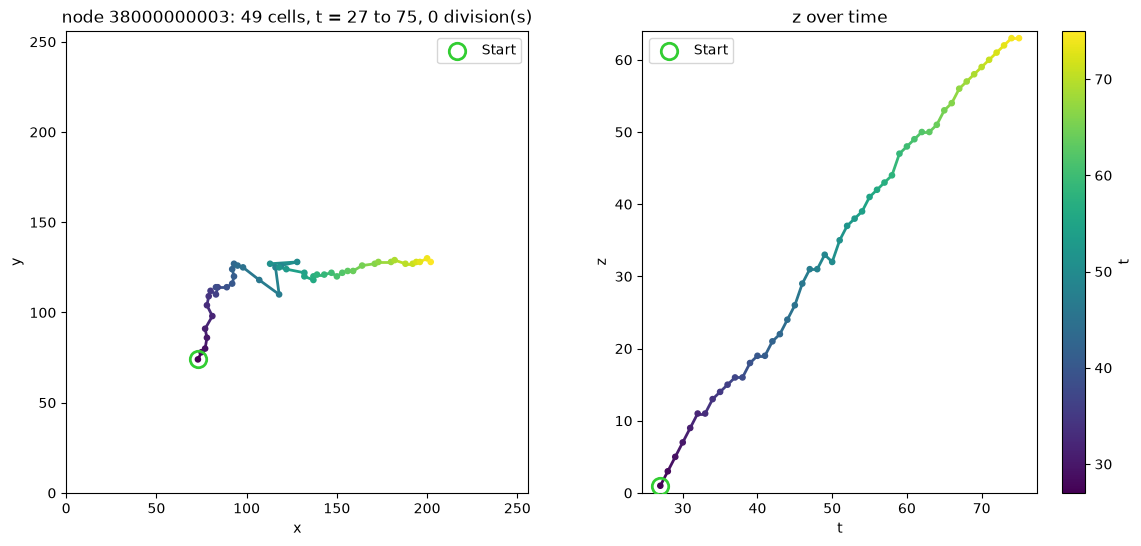

In [ ]:
node_ids = plot_trajectory(gt_graph, root=38000000003)     # a specific starting cell

,edges,share,stolen
kind,,,
correct,3,0.06,0
wrong partner,0,0.00,0
no link,42,0.84,0
undetected,5,0.10,0


array([[<Axes: title={'center': '50 ground-truth edges'}, xlabel='ground-truth edges'>,
        <Axes: title={'center': 'verdicts over time'}, xlabel='t', ylabel='edges'>],
       [<Axes: title={'center': 'how close the right child came to winning'}, xlabel='chosen − true distance (um)', ylabel='edges'>,
        <Axes: title={'center': 'how far the cell appeared to move'}, xlabel='parent to true child (um)', ylabel='edges'>]],
      dtype=object)

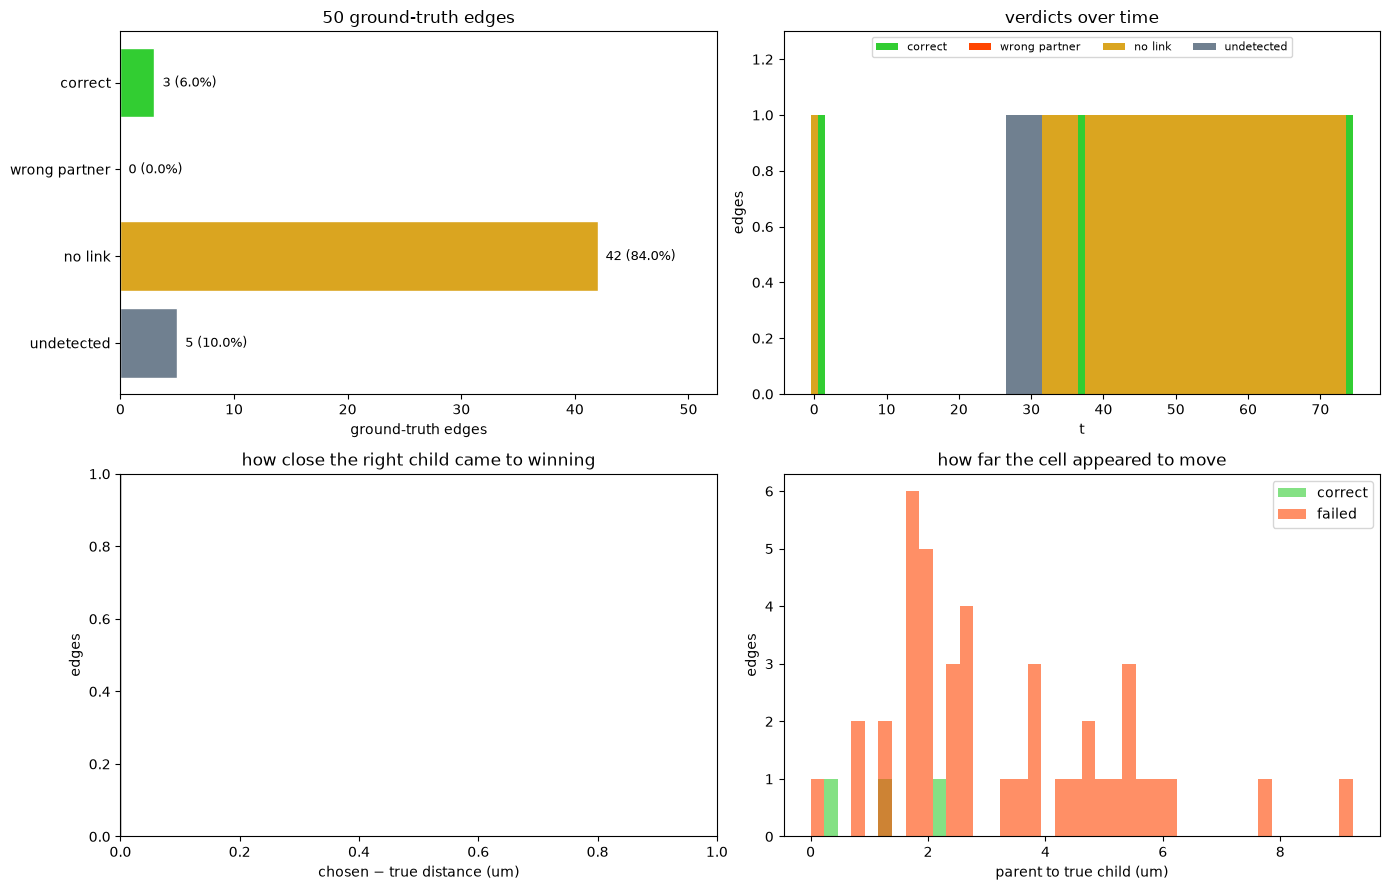

In [ ]:
# One row per ground-truth edge, saying what we did with it. Needs the graph to
# have been matched, which the evaluate call above did.
errors = link_errors(graph, gt_graph, scale=SCALE)
display(error_report(errors))

plot_error_summary(errors)

In [ ]:
# The frame that went worst, then the single link we lost by the widest margin.
# Swap the query for kind == 'no link' to look at the parents we left childless.
worst_frame = errors[errors["kind"] != "correct"]["t"].value_counts().idxmax()
worst_link = errors.query("kind == 'wrong partner'").sort_values("margin").iloc[0]

plt.figure(figsize=(9, 9))
plot_error_map(graph, errors, t=worst_frame)

plot_error_neighbourhood(graph, worst_link, radius=10.0)

IndexError: single positional indexer is out-of-bounds

Done !